In [2]:
import pandas as pd
import numpy as np

#agar mudah, letakkan file data dalam satu folder dengan file jupiter notebook nya
data = pd.read_csv("comentar_instagram.csv", sep=";")
data.head()


,comment_id,parent_id,type,username,comment,like_count,time
0,"1,79043E+16",NaN,Main Comment,gwiyomi_chan,Love it 💕💕💕,8.0,21/09/2026 06:19
1,"1,81145E+16",NaN,Main Comment,anggunwibowo90,Cuma jangan hilangkan menu americano blueberry...,3.0,29/09/2026 01:23
2,"1,78695E+16","1,81145E+16",Reply to @anggunwibowo90,kopikenangan.id,"Hi Kak @anggunwibowo90, terima kasih atas masu...",0.0,29/09/2026 01:25
3,"1,83737E+16","1,81145E+16",Reply to @anggunwibowo90,anggunwibowo90,@kopikenangan.id iya ka soalnya udah ga keluar...,0.0,29/09/2026 02:12
4,"1,86226E+16",NaN,Main Comment,saraaxynn,Sebagai pencinta taro dan haechan ini adalah c...,10.0,22/09/2026 00:13



<div align="center" style="color: blue;">
  <h1>Explain</h1>
</div>

<div align="center" style="border: 1px solid #d1d5db; border-radius: 10px; padding: 15px; margin: 15px auto; max-width: 750px;">
  <img
    src="Gambar/Gambar%201%20SMA.jpeg"
    alt="Penjelasan bagian code pertama"
    width="700"
    style="display: block; width: 100%; max-width: 700px; height: auto; border-radius: 8px;"
  >
</div>


In [3]:
# ------ Case Folding --------
# gunakan fungsi Series.str.lower() pada Pandas
data['comment'] = data['comment'].str.lower()

print('Case Folding Result : \n')
print(data['comment'].head(5))


Case Folding Result : 

0                                          love it 💕💕💕
1    cuma jangan hilangkan menu americano blueberry...
2    hi kak @anggunwibowo90, terima kasih atas masu...
3    @kopikenangan.id iya ka soalnya udah ga keluar...
4    sebagai pencinta taro dan haechan ini adalah c...
Name: comment, dtype: str



<div align="center" style="color: blue;">
  <h1>Explain</h1>
</div>

<div align="center" style="border: 1px solid #d1d5db; border-radius: 10px; padding: 15px; margin: 15px auto; max-width: 750px;">
  <img
    src="Gambar/Gambar 2 SMA.jpeg"
    alt="Penjelasan bagian code pertama"
    width="700"
    style="display: block; width: 100%; max-width: 700px; height: auto; border-radius: 8px;"
  >
</div>


In [4]:
import string
import re #regex library

# import word_tokenize & FreqDist from NLTK
from nltk.tokenize import word_tokenize
from nltk.probability import FreqDist
import nltk
nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)

# ------ Tokenizing ---------

def remove_tweet_special(text):
    # 1. Cek jika nilai kosong (NaN/float), kembalikan string kosong
    if pd.isna(text):
        return ""
    
    # 2. Paksa konversi ke string untuk berjaga-jaga
    text = str(text)
    
    # Proses pembersihan
    text = text.replace('\\t', " ").replace('\\n', " ").replace('\\u', " ").replace('\\', "")
    text = text.encode('ascii', 'replace').decode('ascii')
    text = ' '.join(re.sub("([@#][A-Za-z0-9]+)|(\\w+:\\/\\/\\S+)", " ", text).split())
    return text.replace("http://", " ").replace("https://", " ")

# Cara panggilnya cukup seperti awal (pastikan untuk import pandas as pd di atas)
data['comment'] = data['comment'].apply(remove_tweet_special)
#remove number
def remove_number(text):
    return  re.sub(r"\d+", "", text)

data['comment'] = data['comment'].apply(remove_number)

#remove punctuation
def remove_punctuation(text):
    return text.translate(str.maketrans("","",string.punctuation))

data['comment'] = data['comment'].apply(remove_punctuation)

#remove whitespace leading & trailing
def remove_whitespace_LT(text):
    return text.strip()

data['comment'] = data['comment'].apply(remove_whitespace_LT)

#remove multiple whitespace into single whitespace
def remove_whitespace_multiple(text):
    return re.sub('\\s+',' ',text)

data['comment'] = data['comment'].apply(remove_whitespace_multiple)

# remove single char
def remove_singl_char(text):
    return re.sub(r"\b[a-zA-Z]\b", "", text)

data['comment'] = data['comment'].apply(remove_singl_char)

# NLTK word tokenize
def word_tokenize_wrapper(text):
    return word_tokenize(text)

data['comment_tokens'] = data['comment'].apply(word_tokenize_wrapper)

print('Tokenizing Result : \n')
print(data['comment_tokens'].head())


Tokenizing Result : 

0                                           [love, it]
1    [cuma, jangan, hilangkan, menu, americano, blu...
2    [hi, kak, terima, kasih, atas, masukkan, yang,...
3    [id, iya, ka, soalnya, udah, ga, keluar, lagi,...
4    [sebagai, pencinta, taro, dan, haechan, ini, a...
Name: comment_tokens, dtype: object



<div align="center" style="color: blue;">
  <h1>Explain</h1>
</div>

<div align="center" style="border: 1px solid #d1d5db; border-radius: 10px; padding: 15px; margin: 15px auto; max-width: 750px;">
  <img
    src="Gambar/Gambar 3 SMA.jpeg"
    alt="Penjelasan bagian code pertama"
    width="700"
    style="display: block; width: 100%; max-width: 700px; height: auto; border-radius: 8px;"
  >
</div>


In [5]:
import nltk
nltk.download('stopwords', quiet=True)
from nltk.corpus import stopwords

# ----------------------- get stopword from NLTK stopword -----------------------
# get stopword indonesia
list_stopwords = stopwords.words('indonesian')

# ---------------------------- manualy add stopword  ------------------------------------
# append additional stopword
list_stopwords.extend(["yg", "dg", "rt", "dgn", "ny", "d", 'klo',
                       'kalo', 'amp', 'biar', 'bikin', 'bilang',
                       'gak', 'ga', 'krn', 'nya', 'nih', 'sih',
                       'si', 'tau', 'tdk', 'tuh', 'utk', 'ya',
                       'jd', 'jgn', 'sdh', 'aja', 'n', 't',
                       'nyg', 'hehe', 'pen', 'u', 'nan', 'loh', 'rt',
                       '&amp', 'yah', 'bisnis', 'pandemi', 'indonesia'])

# convert list to dictionary
list_stopwords = set(list_stopwords)

#remove stopword pada list token
def stopwords_removal(words):
    return [word for word in words if word not in list_stopwords]

data['comment_tokens_WSW'] = data['comment_tokens'].apply(stopwords_removal)

print(data['comment_tokens_WSW'].head())


0                                           [love, it]
1    [hilangkan, menu, americano, blueberry, enak, ...
2    [hi, kak, terima, kasih, masukkan, saran, kaka...
3    [id, iya, ka, udah, menu, best, fav, americano...
4            [pencinta, taro, haechan, combo, terbaik]
Name: comment_tokens_WSW, dtype: object



<div align="center" style="color: blue;">
  <h1>Explain</h1>
</div>

<div align="center" style="border: 1px solid #d1d5db; border-radius: 10px; padding: 15px; margin: 15px auto; max-width: 750px;">
  <img
    src="Gambar/Gambar 4 SMA.jpeg"
    alt="Penjelasan bagian code pertama"
    width="700"
    style="display: block; width: 100%; max-width: 700px; height: auto; border-radius: 8px;"
  >
</div>


In [ ]:
normalizad_word = pd.read_csv("normalisasi_kata.csv", sep=";")

normalizad_word_dict = {}

for index, row in normalizad_word.iterrows():
    if row['before'] not in normalizad_word_dict:
        normalizad_word_dict[row['before']] = row['after']

def normalized_term(document):
    return [normalizad_word_dict[term] if term in normalizad_word_dict else term for term in document]

data['comment_normalized'] = data['comment_tokens_WSW'].apply(normalized_term)

print(data['comment_normalized'].head(10))


0                                           [love, it]
1    [hilangkan, menu, americano, blueberry, enak, ...
2    [hi, kak, terima, kasih, masukkan, saran, kaka...
3    [id, iya, ka, udah, menu, best, fav, americano...
4            [pencinta, taro, haechan, combo, terbaik]
5                 [siappp, mahh, varian, minum, heheh]
6                                [bingung, suka, taro]
7                              [ehhh, iya, suka, aman]
8          [kmrn, kebakaran, perkara, lope, ungu, wkw]
9                                               [ungu]
Name: comment_normalized, dtype: object



<div align="center" style="color: blue;">
  <h1>Explain</h1>
</div>

<div align="center" style="border: 1px solid #d1d5db; border-radius: 10px; padding: 15px; margin: 15px auto; max-width: 750px;">
  <img
    src="Gambar/Gambar 5 SMA.jpeg"
    alt="Penjelasan bagian code pertama"
    width="700"
    style="display: block; width: 100%; max-width: 700px; height: auto; border-radius: 8px;"
  >
</div>


In [7]:

# import Sastrawi package
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
import swifter

# create stemmer
factory = StemmerFactory()
stemmer = factory.create_stemmer()

# stemmed
def stemmed_wrapper(term):
    return stemmer.stem(term)

term_dict = {}

for document in data['comment_normalized']:
    for term in document:
        if term not in term_dict:
            term_dict[term] = ' '

print(len(term_dict))


for term in term_dict:
    term_dict[term] = stemmed_wrapper(term)



# Tambahkan **kwargs agar parameter convert_dtype dari swifter diabaikan
def get_stemmed_term(document, **kwargs):
    if not isinstance(document, list):
        return []
    
    return [term_dict.get(term, term) for term in document]

# Terapkan kembali dengan swifter
data['comment_tokens_stemmed'] = data['comment_normalized'].swifter.apply(get_stemmed_term)



c:\Users\hp\Documents\Pemograman BI\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


1536


Pandas Apply: 100%|██████████| 738/738 [00:00<00:00, 138323.19it/s]


In [8]:
# Lebih aman dari pergeseran urutan kolom
document = data['comment_tokens_stemmed'].tolist()

document[0:5]


[['love', 'it'],
 ['hilang', 'menu', 'americano', 'blueberry', 'enak', 'bgt'],
 ['hi',
  'kak',
  'terima',
  'kasih',
  'masuk',
  'saran',
  'kakak',
  'catat',
  'masuk',
  'tim',
  'kopi',
  'kenang',
  'depan',
  'tingkat',
  'layan',
  'sn'],
 ['id',
  'iya',
  'ka',
  'udah',
  'menu',
  'best',
  'fav',
  'americano',
  'blueberry',
  'kopken',
  'skrg'],
 ['cinta', 'taro', 'haechan', 'combo', 'baik']]


<div align="center" style="color: blue;">
  <h1>Explain</h1>
</div>

<div align="center" style="border: 1px solid #d1d5db; border-radius: 10px; padding: 15px; margin: 15px auto; max-width: 750px;">
  <img
    src="Gambar/Gambar 6 SMA.jpeg"
    alt="Penjelasan bagian code pertama"
    width="700"
    style="display: block; width: 100%; max-width: 700px; height: auto; border-radius: 8px;"
  >
</div>


In [9]:
doc_clean = data['comment_tokens_stemmed']
doc_clean


import gensim
from gensim import corpora

dictionary = corpora.Dictionary(doc_clean)
print(dictionary)

doc_term_matrix = [dictionary.doc2bow(doc) for doc in doc_clean]



Dictionary<1460 unique tokens: ['it', 'love', 'americano', 'bgt', 'blueberry']...>



<div align="center" style="color: blue;">
  <h1>Explain</h1>
</div>

<div align="center" style="border: 1px solid #d1d5db; border-radius: 10px; padding: 15px; margin: 15px auto; max-width: 750px;">
  <img
    src="Gambar/Gambar 7 SMA.jpeg"
    alt="Penjelasan bagian code pertama"
    width="700"
    style="display: block; width: 100%; max-width: 700px; height: auto; border-radius: 8px;"
  >
</div>


In [10]:
# Creating the object for LDA model using gensim library
Lda = gensim.models.ldamodel.LdaModel

total_topics = 5 # jumlah topik yang akan di extract
number_words = 15 # jumlah kata per topik


# Running and Trainign LDA model on the document term matrix.
lda_model = Lda(doc_term_matrix, num_topics=total_topics, id2word = dictionary, passes=50)

lda_model.show_topics(num_topics=total_topics, num_words=number_words)



[(0,
  '0.028*"dapet" + 0.027*"udah" + 0.019*"minnn" + 0.017*"restock" + 0.015*"minn" + 0.012*"cup" + 0.010*"min" + 0.010*"gk" + 0.010*"sleeve" + 0.010*"kopi" + 0.010*"stock" + 0.009*"id" + 0.008*"gas" + 0.007*"dpt" + 0.007*"banget"'),
 (1,
  '0.027*"fandom" + 0.023*"ungu" + 0.017*"victim" + 0.016*"playing" + 0.013*"sampe" + 0.012*"lu" + 0.012*"idol" + 0.011*"ganti" + 0.010*"beli" + 0.010*"ba" + 0.010*"ngatain" + 0.010*"bts" + 0.009*"ijo" + 0.009*"malu" + 0.008*"duluan"'),
 (2,
  '0.017*"wa" + 0.016*"kakk" + 0.013*"kopken" + 0.012*"ku" + 0.012*"gift" + 0.010*"set" + 0.009*"langsung" + 0.009*"outlet" + 0.009*"eh" + 0.009*"yaa" + 0.008*"ngga" + 0.007*"pas" + 0.007*"emang" + 0.007*"fans" + 0.007*"outletnya"'),
 (3,
  '0.049*"min" + 0.027*"taro" + 0.015*"id" + 0.015*"menu" + 0.011*"banana" + 0.010*"udah" + 0.010*"dapet" + 0.010*"bgt" + 0.009*"kopken" + 0.009*"enak" + 0.008*"blm" + 0.008*"muncul" + 0.007*"matcha" + 0.007*"banget" + 0.007*"dah"'),
 (4,
  '0.072*"kk" + 0.070*"daerah" + 0.064*


<div align="center" style="color: blue;">
  <h1>Explain</h1>
</div>

<div align="center" style="border: 1px solid #d1d5db; border-radius: 10px; padding: 15px; margin: 15px auto; max-width: 750px;">
  <img
    src="Gambar/Gambar 8 SMA.jpeg"
    alt="Penjelasan bagian code pertama"
    width="700"
    style="display: block; width: 100%; max-width: 700px; height: auto; border-radius: 8px;"
  >
</div>


In [11]:
#Dominant topic and its percentage contribution in each topic
def format_topics_sentences(ldamodel=None, corpus=doc_term_matrix, texts=document):
    # Init output
    sent_topics_df = pd.DataFrame()

    # Get main topic in each document
    for i, row_list in enumerate(ldamodel[corpus]):
        row = row_list[0] if ldamodel.per_word_topics else row_list
        # print(row)
        row = sorted(row, key=lambda x: (x[1]), reverse=True)
        # Get the Dominant topic, Perc Contribution and Keywords for each document
        for j, (topic_num, prop_topic) in enumerate(row):
            if j == 0:  # => dominant topic
                wp = ldamodel.show_topic(topic_num)
                topic_keywords = ", ".join([word for word, prop in wp])
                sent_topics_df = sent_topics_df.append(pd.Series([int(topic_num), round(prop_topic,4), topic_keywords]), ignore_index=True)
            else:
                break
    sent_topics_df.columns = ['Dominant_Topic', 'Perc_Contribution', 'Topic_Keywords']

    # Add original text to the end of the output
    contents = pd.Series(texts)
    sent_topics_df = pd.concat([sent_topics_df, contents], axis=1)
    return(sent_topics_df)


# Redefining the function to fix the 'append' AttributeError by using list collection
def format_topics_sentences(ldamodel=None, corpus=doc_term_matrix, texts=doc_clean):
    sent_topics_data = []

    # Get main topic in each document
    for i, row_list in enumerate(ldamodel[corpus]):
        row = row_list[0] if ldamodel.per_word_topics else row_list
        row = sorted(row, key=lambda x: (x[1]), reverse=True)
        # Get the Dominant topic, Perc Contribution and Keywords for each document
        for j, (topic_num, prop_topic) in enumerate(row):
            if j == 0:  # => dominant topic
                wp = ldamodel.show_topic(topic_num)
                topic_keywords = ", ".join([word for word, prop in wp])
                sent_topics_data.append([int(topic_num), round(prop_topic, 4), topic_keywords])
                break
            else:
                break

    sent_topics_df = pd.DataFrame(sent_topics_data, columns=['Dominant_Topic', 'Perc_Contribution', 'Topic_Keywords'])

    # Add original text to the end of the output
    contents = pd.Series(texts).reset_index(drop=True)
    sent_topics_df = pd.concat([sent_topics_df, contents], axis=1)
    return sent_topics_df

# Run the corrected function
df_topic_sents_keywords = format_topics_sentences(ldamodel=lda_model, corpus=doc_term_matrix, texts=doc_clean)

# Format output
df_dominant_topic = df_topic_sents_keywords.reset_index()
df_dominant_topic.columns = ['Document_No', 'Dominant_Topic', 'Topic_Perc_Contrib', 'Keywords', 'Text']
print(df_dominant_topic.head(10))



   Document_No  Dominant_Topic  Topic_Perc_Contrib  \
0            0               4              0.7301   
1            1               3              0.7439   
2            2               4              0.9526   
3            3               3              0.9329   
4            4               0              0.5763   
5            5               2              0.8652   
6            6               3              0.7993   
7            7               3              0.8394   
8            8               1              0.8856   
9            9               1              0.6000   

                                            Keywords  \
0  kk, daerah, jastip, kak, dapet, hi, udah, dm, ...   
1  min, taro, id, menu, banana, udah, dapet, bgt,...   
2  kk, daerah, jastip, kak, dapet, hi, udah, dm, ...   
3  min, taro, id, menu, banana, udah, dapet, bgt,...   
4  dapet, udah, minnn, restock, minn, cup, min, g...   
5  wa, kakk, kopken, ku, gift, set, langsung, out...   
6  min, taro,


<div align="center" style="color: blue;">
  <h1>Explain</h1>
</div>

<div align="center" style="border: 1px solid #d1d5db; border-radius: 10px; padding: 15px; margin: 15px auto; max-width: 750px;">
  <img
    src="Gambar/Gambar 9 SMA.jpeg"
    alt="Penjelasan bagian code pertama"
    width="700"
    style="display: block; width: 100%; max-width: 700px; height: auto; border-radius: 8px;"
  >
</div>


In [15]:
import os
import pickle
import numpy as np
import gensim
import pyLDAvis
import matplotlib.pyplot as plt
import seaborn as sns

# PERBAIKAN 1: Gunakan gensim_models untuk pyLDAvis versi terbaru
import pyLDAvis.gensim_models as gensimvis 

pyLDAvis.enable_notebook()

# Pastikan dictionary terdefinisi
if 'dictionary' not in globals():
    from gensim import corpora
    dictionary = corpora.Dictionary(doc_clean)

# Setup Corpus
corpus = [dictionary.doc2bow(text) for text in doc_clean]

total_topics = 5 # Pindahkan definisi total_topics ke luar agar variabel LDAvis_data_filepath bisa membacanya
LDAvis_data_filepath = os.path.join('ldavis_prepared_' + str(total_topics))

# Re-train model jika lda_model tidak ditemukan di memori
if 'lda_model' not in globals():
    print("Variabel lda_model tidak ditemukan. Melatih ulang model LDA secara otomatis...")
    Lda = gensim.models.ldamodel.LdaModel
    lda_model = Lda(corpus, num_topics=total_topics, id2word=dictionary, passes=50)

# Proses penyiapan visualisasi pyLDAvis
if 1 == 1:
    # Gunakan gensimvis.prepare sesuai versi modul yang aman
    LDAvis_prepared = gensimvis.prepare(lda_model, corpus, dictionary)
    
    # PERBAIKAN 2: Ekstrak nilai real sebelum disimpan/ditampilkan untuk menghindari error JSON complex128
    LDAvis_prepared.topic_coordinates['x'] = np.real(LDAvis_prepared.topic_coordinates['x'])
    LDAvis_prepared.topic_coordinates['y'] = np.real(LDAvis_prepared.topic_coordinates['y'])
    
    # Simpan ke file pickle
    with open(LDAvis_data_filepath, 'wb') as f:
        pickle.dump(LDAvis_prepared, f)

# Muat kembali data pyLDAvis yang sudah disiapkan dari disk
with open(LDAvis_data_filepath, 'rb') as f:
    LDAvis_prepared = pickle.load(f)

# Simpan sebagai file HTML
pyLDAvis.save_html(LDAvis_prepared, 'ldavis_prepared_'+ str(total_topics) +'.html')

# Tampilkan di cell Jupyter Notebook
LDAvis_prepared




PreparedData(topic_coordinates=              x         y  topics  cluster       Freq
topic                                                
4      0.193851  0.104846       1        1  26.600252
3      0.005095 -0.137726       2        1  22.341876
1     -0.166155  0.116014       3        1  20.726914
0     -0.001329 -0.098301       4        1  15.435469
2     -0.031462  0.015167       5        1  14.895489, topic_info=       Term       Freq      Total Category  logprob  loglift
619      kk  81.000000  81.000000  Default  30.0000  30.0000
425  daerah  80.000000  80.000000  Default  29.0000  29.0000
932  jastip  73.000000  73.000000  Default  28.0000  28.0000
11      kak  61.000000  61.000000  Default  27.0000  27.0000
331     min  56.000000  56.000000  Default  26.0000  26.0000
..      ...        ...        ...      ...      ...      ...
182     apk   3.198921  12.485692   Topic5  -5.2859   0.5423
11      kak   4.005472  61.696457   Topic5  -5.0610  -0.8305
95   fandom   3.502188  27.521311   Topic5  -5.1953  -0.1575
7      menu   3.434470  24.726420   Topic5  -5.2148  -0.0699
105    idol   2.950314  15.044307   Topic5  -5.3668   0.2750

[284 rows x 6 columns], token_table=      Topic      Freq    Term
term                         
548       1  0.228192    abis
548       2  0.228192    abis
548       4  0.456384    abis
601       2  0.835216   adain
601       4  0.167043   adain
...     ...       ...     ...
195       2  0.215132     yaa
195       3  0.143421     yaa
195       4  0.071711     yaa
195       5  0.358553     yaa
647       5  0.930480  yeayyy

[402 rows x 3 columns], R=30, lambda_step=0.01, plot_opts={'xlab': 'PC1', 'ylab': 'PC2'}, topic_order=[5, 4, 2, 1, 3])


<div align="center" style="color: blue;">
  <h1>Explain</h1>
</div>

<div align="center" style="border: 1px solid #d1d5db; border-radius: 10px; padding: 15px; margin: 15px auto; max-width: 750px;">
  <img
    src="Gambar/Gambar 10 SMA.jpeg"
    alt="Penjelasan bagian code pertama"
    width="700"
    style="display: block; width: 100%; max-width: 700px; height: auto; border-radius: 8px;"
  >
</div>


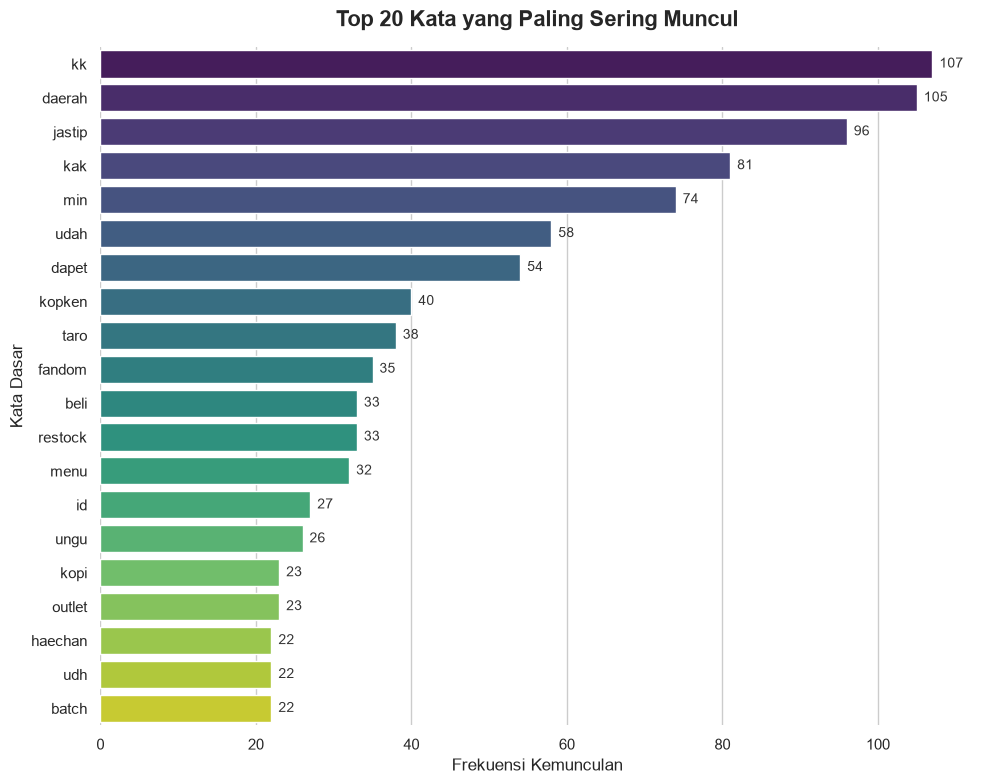

In [13]:
import pandas as pd
from collections import Counter
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Ekstrak dan hitung frekuensi kata dari kolom dataset utama (misal: data['comment_tokens_stemmed'])
semua_kata = [kata for baris in data['comment_tokens_stemmed'] for kata in baris]
hitung_kata = Counter(semua_kata)

# 2. Ubah 20 kata terbanyak menjadi DataFrame (tanpa tanda kutip saat dipanggil)
df_top20 = pd.DataFrame(hitung_kata.most_common(20), columns=['kata', 'frekuensi'])

# 3. Mulai Visualisasi
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 8))

# Masukkan variabel df_top20 langsung, BUKAN 'df_top20'
ax = sns.barplot(
    x='frekuensi', 
    y='kata', 
    data=df_top20, 
    palette="viridis"
)

# Tambahkan label angka persis di ujung kanan setiap batang grafik
for container in ax.containers:
    ax.bar_label(container, padding=5, fontsize=10, color='#333333')

# Pengaturan tipografi dan layout
plt.title('Top 20 Kata yang Paling Sering Muncul', fontsize=16, fontweight='bold', pad=15)
plt.xlabel('Frekuensi Kemunculan', fontsize=12)
plt.ylabel('Kata Dasar', fontsize=12)

sns.despine(bottom=True, left=True)
plt.tight_layout()
plt.show()


<div align="center" style="color: blue;">
  <h1>Explain</h1>
</div>

<div align="center" style="border: 1px solid #d1d5db; border-radius: 10px; padding: 15px; margin: 15px auto; max-width: 750px;">
  <img
    src="Gambar/Gambar 11 SMA.jpeg"
    alt="Penjelasan bagian code pertama"
    width="700"
    style="display: block; width: 100%; max-width: 700px; height: auto; border-radius: 8px;"
  >
</div>


In [14]:
def get_topic_details(ldamodel, corpus):
    rows = []
    for i, row in enumerate(ldamodel[corpus]):
        row = sorted(row, key=lambda x: x[1], reverse=True)
        for j, (topic_num, prop_topic) in enumerate(row):
            if j == 0:  # Dominant topic
                wp = ldamodel.show_topic(topic_num)
                rows.append([topic_num, prop_topic])

    topic_details_df = pd.DataFrame(rows, columns=['Dominant_Topic', '%Score'])
    return topic_details_df

# Run get_topic_details function and check the results
# Mengubah ldamodel menjadi lda_model yang merupakan variabel model Anda
print(get_topic_details(lda_model, corpus))


import pandas as pd
import numpy as np

# Add original text to topic details in a dataframe
contents = pd.DataFrame({'Original text': doc_clean})
topic_details = pd.concat([get_topic_details(lda_model, corpus), contents], axis=1)
topic_details.head()

#create flag for text highest associated with topic 3
topic_details['flag']=np.where((topic_details['Dominant_Topic'] == 3.0),1,0)
topic_details.head()


#count the value of the dominant topics
count = topic_details['flag'].value_counts()
print(count)



     Dominant_Topic    %Score
0                 4  0.730056
1                 3  0.743918
2                 4  0.952617
3                 3  0.932880
4                 0  0.575737
..              ...       ...
733               4  0.796451
734               4  0.938027
735               1  0.717319
736               4  0.926296
737               0  0.910466

[738 rows x 2 columns]
flag
0    587
1    151
Name: count, dtype: int64



<div align="center" style="color: blue;">
  <h1>Explain</h1>
</div>

<div align="center" style="border: 1px solid #d1d5db; border-radius: 10px; padding: 15px; margin: 15px auto; max-width: 750px;">
  <img
    src="Gambar/Gambar 12 SMA.jpeg"
    alt="Penjelasan bagian code pertama"
    width="700"
    style="display: block; width: 100%; max-width: 700px; height: auto; border-radius: 8px;"
  >
</div>
